In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/PlantVillage"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Folders:", os.listdir(extract_path)[:10])

FileNotFoundError: [Errno 2] No such file or directory: '/content/archive.zip'

In [ ]:
import os

file_path = "/content/archive.zip"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")

    with open(file_path, "rb") as f:
        print("File signature:", f.read(20))


In [ ]:
import zipfile

zip_path = "/content/archive.zip"

with open(zip_path, "rb") as f:
    print("First 4 bytes:", f.read(4))

try:
    with zipfile.ZipFile(zip_path, 'r') as z:
        print("ZIP detected successfully!")
        print("Number of files:", len(z.namelist()))
        print("First 10 entries:")
        print(z.namelist()[:10])

        print("Testing archive integrity...")
        print("Result:", z.testzip())

except Exception as e:
    print("ZIP ERROR:", repr(e))


In [ ]:
import os

path = "/content/archive.zip"

with open(path, "rb") as f:
    f.seek(-22, 2)
    last_bytes = f.read(22)

print("File size:", os.path.getsize(path))
print("Last 22 bytes:", last_bytes)
print("ZIP end signature found:", b'PK\x05\x06' in last_bytes)

In [ ]:
from google.colab import files

uploaded = files.upload()


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

!pip install -q kaggle

print("Kaggle API configured successfully!")

In [ ]:
!kaggle datasets list -s plantdisease


In [ ]:
import os

dataset_path = "/content/plantvillage_data"
os.makedirs(dataset_path, exist_ok=True)

!kaggle datasets download -d emmarex/plantdisease -p /content/plantvillage_data --unzip

In [ ]:
import os

base_path = "/content/plantvillage_data"

print("Main folders:", os.listdir(base_path))

for root, dirs, files in os.walk(base_path):
    images = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    if images:
        print(root, ":", len(images), "images")

In [ ]:
import os

if os.path.exists("/content/kaggle.json"):
    os.remove("/content/kaggle.json")

print("Temporary credential copy removed.")

In [ ]:
import os

base_path = "/content/plantvillage_data"

print("Main folders:", os.listdir(base_path))

for root, dirs, files in os.walk(base_path):
    images = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if images:
        print(root, ":", len(images), "images")


In [ ]:
import os

base_path = "/content/plantvillage_data/PlantVillage"

classes = sorted([
    folder for folder in os.listdir(base_path)
    if os.path.isdir(os.path.join(base_path, folder))
])

print("Number of classes:", len(classes))
print("\nDisease classes:")

total_images = 0

for class_name in classes:
    folder_path = os.path.join(base_path, class_name)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    total_images += len(images)

    print(class_name, ":", len(images))

print("\nTotal images:", total_images)

In [ ]:
import os
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

base_path = "/content/plantvillage_data/PlantVillage"

image_paths = []
labels = []

classes = sorted([
    folder for folder in os.listdir(base_path)
    if os.path.isdir(os.path.join(base_path, folder))
])

for class_name in classes:
    folder_path = os.path.join(base_path, class_name)

    for file in os.listdir(folder_path):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(folder_path, file))
            labels.append(class_name)

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

print("\nNumber of classes:", len(classes))

In [ ]:
import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32

# Map disease names to numerical labels
class_names = sorted(classes)

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

y_train_num = [class_to_index[label] for label in y_train]
y_val_num = [class_to_index[label] for label in y_val]
y_test_num = [class_to_index[label] for label in y_test]

print("Number of classes:", len(class_names))
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

print("\nClass label mapping:")

for name, index in class_to_index.items():
    print(index, ":", name)

In [ ]:
def preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train_num)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val_num)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test_num)
)

train_dataset = (
    train_dataset
    .shuffle(2000, seed=42)
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

In [ ]:
images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # First convolution block
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Second convolution block
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Third convolution block
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Classification layers
    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(15, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)

In [ ]:
model.save("/content/plant_disease_model.keras")

In [ ]:
from google.colab import files
files.download("/content/plant_disease_model.keras")


In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Classroom', 'english.docx', 'Flipped Classroom Activity_PPT_FORMAT.gslides', 'mqps.zip', 'English-Artist.docx', 'one day diet chart.xlsx', 'The Masked Therapist.docx', 'Childhood Trauma and Psychological Repression in The Silent Patient”.docx', 'Screenshot_2025-11-30-17-14-24-87_944a2809ea1b4cda6ef12d1db9048ed3.jpg', 'Screenshot_2026-06-10-14-34-25-48_ec576d6a4b63b6521ff16f5575cc4da0.jpg', '1RN24EC013_10M.jpeg', 'in.gov.uidai-ADHAR-465ec69eab5f5cadf6bc53386bc7cd1a.jpeg', '3.1.gdoc', 'SIH2026-IDEA-Presentation-Format (2).pptx.pptx', 'Sensor data.gdoc', 'BAASC', 'The Imposters_Round1.pdf', '2028 Batch PodAi Registration.xlsx', '3. SeventhSense_Batches 13 to 24.xlsx', 'PlantCity_Dataset']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"

print("Files inside PlantCity_Dataset:")
print(os.listdir(dataset_path))

Files inside PlantCity_Dataset:
[]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'faria birthday', 'ethnic day2k24', 'Receipt exam2.pdf', 'cet documents', '881130169178884_signed.pdf', 'Film', 'Untitled form (2).gform', 'Google Keep Document.gdoc', 'Mysore .gdoc', 'mysore', 'Untitled spreadsheet.gsheet', 'Classroom', 'Duplicate_Receipt-3_copy.pdf', 'IMG-20251009-WA0005.jpg', 'so in 3rd sem wht shd i start with?.gsheet', 'give me a shedule for next two months (2).gsheet', 'which course in c do u recommend for 8 weeks.gdoc', 'i am in 2nd year of engineering ece and wht shd i....gdoc', 'give me a shedule for next two months (1).gsheet', 'give me a shedule for next two months.gsheet', 'Audio overviews', 'DOC-20251227-WA0013.gdoc', 'chandana.gdoc', 'VLSI GROUP.gform', 'VLSI GROUP (Responses).gsheet', 'Copy of VLSI GROUP (Responses).gsheet', 'Copy of VLSI GROUP.gform', 'Screenshot_2026-02-08-21-57-22-84_944a2809ea1b4cda6ef12d1db9048ed3.jpg', 'Untitled document (1).gdoc', 'Advanced verilog PS.gdoc', 'Solution Key & Error List(AV).gdoc', 'Testbenches(AV

In [ ]:
dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"
print(os.listdir(dataset_path))

['test.zip', 'train.zip']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"

for file in os.listdir(dataset_path):
    file_path = os.path.join(dataset_path, file)
    size_gb = os.path.getsize(file_path) / (1024**3)
    print(file, ":", round(size_gb, 2), "GB")

test.zip : 1.05 GB
train.zip : 5.71 GB


In [ ]:
import zipfile
import os

dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"

train_zip = os.path.join(dataset_path, "train.zip")
test_zip = os.path.join(dataset_path, "test.zip")

for name, path in [("TRAIN", train_zip), ("TEST", test_zip)]:
    print("\n==========", name, "==========")

    with zipfile.ZipFile(path, 'r') as z:
        files = z.namelist()
        print("Total entries:", len(files))
        print("First 20 entries:")
        for f in files[:20]:
            print(f)


========== TRAIN ==========
Total entries: 41658
First 20 entries:
train/Apple black_spot/
train/Apple black_spot/1.jpg
train/Apple black_spot/10.jpg
train/Apple black_spot/100.jpg
train/Apple black_spot/101.jpg
train/Apple black_spot/102.jpg
train/Apple black_spot/103.jpg
train/Apple black_spot/104.jpg
train/Apple black_spot/105.jpg
train/Apple black_spot/106.jpg
train/Apple black_spot/107.jpg
train/Apple black_spot/108.jpg
train/Apple black_spot/109.jpg
train/Apple black_spot/11.jpg
train/Apple black_spot/110.jpg
train/Apple black_spot/111.jpg
train/Apple black_spot/112.jpg
train/Apple black_spot/113.jpg
train/Apple black_spot/114.jpg
train/Apple black_spot/115.jpg

========== TEST ==========
Total entries: 10719
First 20 entries:
test/Apple black_spot/
test/Apple black_spot/1.jpg
test/Apple black_spot/10.jpg
test/Apple black_spot/100.jpg
test/Apple black_spot/101.jpg
test/Apple black_spot/102.jpg
test/Apple black_spot/11.jpg
test/Apple black_spot/12.jpg
test/Apple black_spot/13.jpg

In [ ]:
import zipfile
from collections import Counter

def inspect_dataset(zip_path, split_name):
    with zipfile.ZipFile(zip_path, 'r') as z:
        class_counts = Counter()

        for name in z.namelist():
            parts = name.strip('/').split('/')

            if len(parts) == 3 and parts[-1].lower().endswith(
                ('.jpg', '.jpeg', '.png')
            ):
                class_name = parts[1]
                class_counts[class_name] += 1

    print(f"\n========== {split_name} ==========")
    print("Total classes:", len(class_counts))
    print("Total images:", sum(class_counts.values()))

    for class_name, count in sorted(class_counts.items()):
        print(f"{class_name}: {count}")

    return class_counts


train_counts = inspect_dataset(train_zip, "TRAIN")
test_counts = inspect_dataset(test_zip, "TEST")

print("\n========== COMPARISON ==========")
print("Matching classes:", set(train_counts) == set(test_counts))
print("Training-only classes:", set(train_counts) - set(test_counts))
print("Testing-only classes:", set(test_counts) - set(train_counts))


========== TRAIN ==========
Total classes: 52
Total images: 41606
Apple Brown_spot: 1060
Apple Normal: 824
Apple black_spot: 469
Apricot Normal: 652
Apricot blight leaf disease: 312
Apricot shot_hole: 832
Bean Fungal_leaf disease: 776
Bean Normal leaf: 900
Bean bean rust image: 500
Bean shot_hole: 392
Cherry Leaf Scorch: 1101
Cherry Normal leaf: 500
Cherry brown_spot: 968
Cherry purple leaf spot: 987
Cherry_shot hole disease: 440
Corn Fungal leaf: 332
Corn Normal leaf: 568
Corn gray leaf spot: 528
Corn holcus_ leaf spot: 432
Fig Blight_leaf disease: 763
Fig Brown spot: 428
Fig normal leaf: 600
Fig_rust leaf: 500
Grape Anthracnose leaf: 996
Grape Brown spot leaf: 640
Grape Downy mildew leaf: 624
Grape Mites_leaf disease: 500
Grape Normal_leaf: 1485
Grape Powdery_mildew leaf: 1208
Grape shot hole leaf disease: 852
Lokat Normal leaf: 501
Pear Black spot _ leaf disease: 904
Pear Normal _leaf: 764
Pear fire blight: 380
Walnut Anthracnose_leaf disease: 648
Walnut Blotch_leaf disease: 1354
W

In [ ]:
import zipfile
import shutil

train_size = 0
test_size = 0

with zipfile.ZipFile(train_zip, 'r') as z:
    train_size = sum(f.file_size for f in z.infolist())

with zipfile.ZipFile(test_zip, 'r') as z:
    test_size = sum(f.file_size for f in z.infolist())

free_space = shutil.disk_usage('/content').free

print("TRAIN extracted size:", round(train_size / (1024**3), 2), "GB")
print("TEST extracted size:", round(test_size / (1024**3), 2), "GB")
print("TOTAL extracted size:", round((train_size + test_size) / (1024**3), 2), "GB")
print("Colab free space:", round(free_space / (1024**3), 2), "GB")

TRAIN extracted size: 5.75 GB
TEST extracted size: 1.05 GB
TOTAL extracted size: 6.81 GB
Colab free space: 112.53 GB


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"

print("Folders inside PlantCity_Dataset:")
for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print("📁", item)
        print("   Subfolders:", len(os.listdir(full_path)))


Folders inside PlantCity_Dataset:


In [ ]:
import os

search_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_path):
    for folder in dirs:
        if folder.lower() in ["train", "test"]:
            print("Found:", os.path.join(root, folder))

In [ ]:
import os

search_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_path):
    for folder in dirs:
        if folder.lower() in ["train", "test"]:
            print("Found:", os.path.join(root, folder))

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"

print("Dataset folder exists:", os.path.exists(dataset_path))
print("\nContents:")

for item in os.listdir(dataset_path):
    path = os.path.join(dataset_path, item)
    if os.path.isfile(path):
        print("FILE:", item)
    else:
        print("FOLDER:", item)

Dataset folder exists: True

Contents:
FILE: test.zip
FILE: train.zip


In [ ]:
import os
import zipfile
from tqdm.auto import tqdm

base_path = "/content/drive/MyDrive/PlantCity_Dataset"
output_path = os.path.join(base_path, "Extracted")

os.makedirs(output_path, exist_ok=True)

for split in ["train", "test"]:

    zip_path = os.path.join(base_path, split + ".zip")

    print(f"\nExtracting {split}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        for file in tqdm(z.infolist(), desc=split):
            z.extract(file, output_path)

    print(f"{split} extraction complete!")

print("\nBoth datasets extracted successfully!")


Extracting train...


train:   0%|          | 0/41658 [00:00<?, ?it/s]

train extraction complete!

Extracting test...


test:   0%|          | 0/10719 [00:00<?, ?it/s]

test extraction complete!

Both datasets extracted successfully!


In [ ]:
import os

base_path = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"

train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

print("TRAIN folder exists:", os.path.exists(train_path))
print("TEST folder exists:", os.path.exists(test_path))

train_classes = sorted(os.listdir(train_path))
test_classes = sorted(os.listdir(test_path))

print("\nTraining classes:", len(train_classes))
print("Testing classes:", len(test_classes))

print("\nClass names:")
for name in train_classes:
    print(name)

print("\nClasses match:", train_classes == test_classes)

TRAIN folder exists: True
TEST folder exists: True

Training classes: 52
Testing classes: 52

Class names:
Apple Brown_spot
Apple Normal
Apple black_spot
Apricot Normal
Apricot blight leaf disease
Apricot shot_hole
Bean Fungal_leaf disease
Bean Normal leaf
Bean bean rust image
Bean shot_hole
Cherry Leaf Scorch
Cherry Normal leaf
Cherry brown_spot
Cherry purple leaf spot
Cherry_shot hole disease
Corn Fungal leaf
Corn Normal leaf
Corn gray leaf spot
Corn holcus_ leaf spot
Fig Blight_leaf disease
Fig Brown spot
Fig normal leaf
Fig_rust leaf
Grape Anthracnose leaf
Grape Brown spot leaf
Grape Downy mildew leaf
Grape Mites_leaf disease
Grape Normal_leaf
Grape Powdery_mildew leaf
Grape shot hole leaf disease
Lokat Normal leaf
Pear Black spot _ leaf disease
Pear Normal _leaf
Pear fire blight
Walnut Anthracnose_leaf disease
Walnut Blotch_leaf disease
Walnut Normal_leaf
Walnut Shot_hole
Walnut leaf gall mite
lokat Leaf_spot
persimmons Brown_spot
tomato Fusarium Wilt
tomato spider mites
tomato ve

In [ ]:
import tensorflow as tf
import os

base_path = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"

train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

class_names = sorted(os.listdir(train_path))
NUM_CLASSES = len(class_names)

# 80% training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

# 20% validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

# Separate test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
    class_names=class_names
)

# Improve data-loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("\n========== DATASET SUMMARY ==========")
print("Number of classes:", NUM_CLASSES)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

print("\nClass names:", class_names)


Found 41606 files belonging to 52 classes.
Using 33285 files for training.
Found 41606 files belonging to 52 classes.
Using 8321 files for validation.
Found 10667 files belonging to 52 classes.

========== DATASET SUMMARY ==========
Number of classes: 52
Training batches: 1041
Validation batches: 261
Testing batches: 334

Class names: ['Apple Brown_spot', 'Apple Normal', 'Apple black_spot', 'Apricot Normal', 'Apricot blight leaf disease', 'Apricot shot_hole', 'Bean Fungal_leaf disease', 'Bean Normal leaf', 'Bean bean rust image', 'Bean shot_hole', 'Cherry Leaf Scorch', 'Cherry Normal leaf', 'Cherry brown_spot', 'Cherry purple leaf spot', 'Cherry_shot hole disease', 'Corn Fungal leaf', 'Corn Normal leaf', 'Corn gray leaf spot', 'Corn holcus_ leaf spot', 'Fig Blight_leaf disease', 'Fig Brown spot', 'Fig normal leaf', 'Fig_rust leaf', 'Grape Anthracnose leaf', 'Grape Brown spot leaf', 'Grape Downy mildew leaf', 'Grape Mites_leaf disease', 'Grape Normal_leaf', 'Grape Powdery_mildew leaf', 

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nAvailable GPU:")
print(tf.config.list_physical_devices('GPU'))

print("\nAvailable CPU:")
print(tf.config.list_physical_devices('CPU'))

# Check whether dataset is still loaded
print("\nTraining dataset available:", 'train_ds' in globals())
print("Validation dataset available:", 'val_ds' in globals())
print("Test dataset available:", 'test_ds' in globals())

TensorFlow version: 2.21.0

Available GPU:
[]

Available CPU:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Training dataset available: False
Validation dataset available: False
Test dataset available: False


In [ ]:
import tensorflow as tf
import os

base_path = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"

train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

class_names = sorted(os.listdir(train_path))
NUM_CLASSES = len(class_names)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
    class_names=class_names
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nDataset restored!")
print("Classes:", NUM_CLASSES)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 40437 files belonging to 52 classes.
Using 32350 files for training.
Found 40437 files belonging to 52 classes.
Using 8087 files for validation.


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PlantCity_Dataset/Extracted/test'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"

print("Folders inside Extracted:")
print(os.listdir(base_path))

Folders inside Extracted:
['train']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/PlantCity_Dataset"

print("Files and folders in PlantCity_Dataset:")
print(os.listdir(dataset_path))


Files and folders in PlantCity_Dataset:
['test.zip', 'train.zip', 'Extracted']


In [ ]:
import zipfile
import os

test_zip = "/content/drive/MyDrive/PlantCity_Dataset/test.zip"
extract_path = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"

with zipfile.ZipFile(test_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Test dataset extracted!")
print("Folders:", os.listdir(extract_path))

Test dataset extracted!
Folders: ['train', 'test']


In [ ]:
import tensorflow as tf
import os

base_path = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"

train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

class_names = sorted(os.listdir(train_path))
NUM_CLASSES = len(class_names)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
    class_names=class_names
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nDataset restored!")
print("Classes:", NUM_CLASSES)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 40437 files belonging to 52 classes.
Using 32350 files for training.
Found 40437 files belonging to 52 classes.
Using 8087 files for validation.
Found 10667 files belonging to 52 classes.

Dataset restored!
Classes: 52
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training batches: 1011
Validation batches: 253
Testing batches: 334


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classifier
inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 preprocessing: 0-255 to -1 to +1
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 52)             │        66,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,324,596 (8.87 MB)

 Trainable params: 66,612 (260.20 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "/content/best_plantcity_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
 240/1011 ━━━━━━━━━━━━━━━━━━━━ 1:50:22 9s/step - accuracy: 0.3363 - loss: 2.6782

KeyboardInterrupt: 

In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G  3.5G  110G   4% /


In [ ]:
import shutil
import os

source = "/content/drive/MyDrive/PlantCity_Dataset/Extracted"
destination = "/content/PlantCity_Dataset"

print("Copying dataset to Colab local storage...")

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Copy completed!")
print("Folders:", os.listdir(destination))

Copying dataset to Colab local storage...
Copy completed!
Folders: ['test', 'train']


In [ ]:
import tensorflow as tf
import os

base_path = "/content/PlantCity_Dataset"

train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

class_names = sorted(os.listdir(train_path))
NUM_CLASSES = len(class_names)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_names=class_names
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", NUM_CLASSES)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 40437 files belonging to 52 classes.
Using 32350 files for training.
Found 40437 files belonging to 52 classes.
Using 8087 files for validation.
Found 10667 files belonging to 52 classes.
Classes: 52
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training batches: 1011
Validation batches: 253
Testing batches: 334


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Preprocessing for MobileNetV2
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(52, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 52)             │        66,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,324,596 (8.87 MB)

 Trainable params: 66,612 (260.20 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "/content/best_plantcity_mobilenetv2.keras",
        monitor="val_accuracy",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
 401/1011 ━━━━━━━━━━━━━━━━━━━━ 1:46 175ms/step - accuracy: 0.4346 - loss: 2.1816

InvalidArgumentError: Graph execution error:

Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) INVALID_ARGUMENT:  Input is empty.
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
	 [[IteratorGetNext/_4]]
  (1) INVALID_ARGUMENT:  Input is empty.
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
0 successful operations.
0 derived errors ignored. [Op:__inference_multi_step_on_iterator_17715]

In [ ]:
import os

base_path = "/content/PlantCity_Dataset"

empty_files = []

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            path = os.path.join(root, file)

            if os.path.getsize(path) == 0:
                empty_files.append(path)

print("Empty image files found:", len(empty_files))

for path in empty_files[:20]:
    print(path)

Empty image files found: 1
/content/PlantCity_Dataset/train/Cherry_shot hole disease/42.jpg


In [ ]:
import os

bad_file = "/content/PlantCity_Dataset/train/Cherry_shot hole disease/42.jpg"

if os.path.exists(bad_file):
    os.remove(bad_file)
    print("Corrupted image removed!")
else:
    print("File already removed.")

print("File exists:", os.path.exists(bad_file))

Corrupted image removed!
File exists: False


In [ ]:
import tensorflow as tf
import os

base_path = "/content/PlantCity_Dataset"
train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

class_names = sorted(os.listdir(train_path))
NUM_CLASSES = len(class_names)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_names=class_names
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", NUM_CLASSES)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("Model still available:", "model" in globals())

Found 40436 files belonging to 52 classes.
Using 32349 files for training.
Found 40436 files belonging to 52 classes.
Using 8087 files for validation.
Found 10667 files belonging to 52 classes.
Classes: 52
Training batches: 1011
Validation batches: 253
Testing batches: 334
Model still available: True


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "/content/best_plantcity_mobilenetv2.keras",
        monitor="val_accuracy",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 271s 268ms/step - accuracy: 0.8259 - loss: 0.5565 - val_accuracy: 0.8814 - val_loss: 0.3837 - learning_rate: 0.0010
Epoch 2/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 299s 245ms/step - accuracy: 0.8765 - loss: 0.3831 - val_accuracy: 0.8966 - val_loss: 0.3265 - learning_rate: 0.0010
Epoch 3/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 248s 245ms/step - accuracy: 0.8928 - loss: 0.3234 - val_accuracy: 0.9131 - val_loss: 0.2738 - learning_rate: 0.0010
Epoch 4/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 217s 201ms/step - accuracy: 0.9041 - loss: 0.2855 - val_accuracy: 0.9133 - val_loss: 0.2713 - learning_rate: 0.0010
Epoch 5/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 198s 195ms/step - accuracy: 0.9112 - loss: 0.2584 - val_accuracy: 0.9183 - val_loss: 0.2537 - learning_rate: 0.0010


In [ ]:
# Save Stage 1 model as backup
model.save("/content/plantcity_mobilenetv2_stage1.keras")

# Unfreeze the pretrained base model
base_model.trainable = True

# Freeze earlier layers; fine-tune only the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# Recompile with a much smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning preparation complete!")
print("Trainable parameters:", model.count_params())
print("Model saved successfully!")

Fine-tuning preparation complete!
Trainable parameters: 2324596
Model saved successfully!


In [ ]:
fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_plantcity_mobilenetv2_finetuned.keras",
        monitor="val_accuracy",
        save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.000001
    )
]

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks
)

Epoch 1/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 249s 226ms/step - accuracy: 0.9365 - loss: 0.1875 - val_accuracy: 0.9351 - val_loss: 0.1922 - learning_rate: 1.0000e-05
Epoch 2/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 227s 204ms/step - accuracy: 0.9518 - loss: 0.1436 - val_accuracy: 0.9472 - val_loss: 0.1616 - learning_rate: 1.0000e-05
Epoch 3/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 247s 244ms/step - accuracy: 0.9620 - loss: 0.1111 - val_accuracy: 0.9508 - val_loss: 0.1496 - learning_rate: 1.0000e-05
Epoch 4/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 209s 207ms/step - accuracy: 0.9700 - loss: 0.0898 - val_accuracy: 0.9550 - val_loss: 0.1393 - learning_rate: 1.0000e-05
Epoch 5/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 266s 211ms/step - accuracy: 0.9757 - loss: 0.0737 - val_accuracy: 0.9567 - val_loss: 0.1321 - learning_rate: 1.0000e-05


In [ ]:
import tensorflow as tf
import os

best_model_path = "/content/best_plantcity_mobilenetv2_finetuned.keras"

if os.path.exists(best_model_path):
    evaluation_model = tf.keras.models.load_model(best_model_path)
    print("Best fine-tuned model loaded!")
else:
    evaluation_model = model
    print("Using current trained model.")

test_loss, test_accuracy = evaluation_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Best fine-tuned model loaded!
334/334 ━━━━━━━━━━━━━━━━━━━━ 71s 189ms/step - accuracy: 0.9640 - loss: 0.5896

========== FINAL TEST RESULTS ==========
Test Accuracy: 96.40%
Test Loss: 0.5896


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Model predictions
y_prob = evaluation_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Detailed classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

# Show classes with lowest recall
class_report = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].sort_values("recall")

print("LOWEST PERFORMING 15 CLASSES:")
display(class_report.head(15).round(4))

print("\nOVERALL PERFORMANCE:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

334/334 ━━━━━━━━━━━━━━━━━━━━ 64s 182ms/step
LOWEST PERFORMING 15 CLASSES:


,precision,recall,f1-score,support
Walnut Shot_hole,0.0000,0.0000,0.0000,231.0
Grape Brown spot leaf,0.9735,0.9188,0.9453,160.0
tomato spider mites,0.9365,0.9291,0.9328,127.0
tomato_healthy_leaf,0.9974,0.9475,0.9718,400.0
Grape Downy mildew leaf,0.9608,0.9484,0.9545,155.0
Walnut Normal_leaf,0.9551,0.9551,0.9551,178.0
tomato_late_blight,0.9758,0.9592,0.9674,294.0
Grape Powdery_mildew leaf,0.9601,0.9601,0.9601,301.0
Grape Anthracnose leaf,0.9339,0.9639,0.9486,249.0
Fig Brown spot,0.9905,0.9720,0.9811,107.0



OVERALL PERFORMANCE:
                                 precision    recall  f1-score   support

               Apple Brown_spot       1.00      1.00      1.00       265
                   Apple Normal       1.00      1.00      1.00       206
               Apple black_spot       1.00      1.00      1.00       102
                 Apricot Normal       1.00      1.00      1.00       163
    Apricot blight leaf disease       0.99      0.98      0.98        90
              Apricot shot_hole       0.93      1.00      0.96       208
       Bean Fungal_leaf disease       1.00      1.00      1.00       194
               Bean Normal leaf       0.94      1.00      0.97       223
           Bean bean rust image       1.00      0.98      0.99       124
                 Bean shot_hole       0.70      0.99      0.82        98
             Cherry Leaf Scorch       0.99      0.99      0.99       282
             Cherry Normal leaf       0.99      0.98      0.99       125
              Cherry brown_s

In [ ]:
import numpy as np
import pandas as pd

target_class = "Walnut Shot_hole"
target_idx = class_names.index(target_class)

# Images that actually belong to Walnut Shot_hole
mask = (y_true == target_idx)

predictions = pd.Series(y_pred[mask]).value_counts()

print("ACTUAL WALNUT SHOT_HOLE IMAGES:", mask.sum())
print("\nWHAT THE MODEL PREDICTED FOR THEM:")

for idx, count in predictions.items():
    print(
        f"{class_names[idx]}: {count} images "
        f"({count / mask.sum() * 100:.2f}%)"
    )

# Check which actual classes are wrongly predicted as Walnut leaf gall mite
gall_idx = class_names.index("Walnut leaf gall mite")
gall_mask = (y_pred == gall_idx)

actual_counts = pd.Series(y_true[gall_mask]).value_counts()

print("\n\nIMAGES PREDICTED AS WALNUT LEAF GALL MITE:")

for idx, count in actual_counts.items():
    print(
        f"Actual: {class_names[idx]}: {count} images"
    )

ACTUAL WALNUT SHOT_HOLE IMAGES: 231

WHAT THE MODEL PREDICTED FOR THEM:
Walnut leaf gall mite: 147 images (63.64%)
Bean shot_hole: 38 images (16.45%)
Apricot shot_hole: 15 images (6.49%)
Bean Normal leaf: 9 images (3.90%)
Walnut Normal_leaf: 8 images (3.46%)
Walnut Anthracnose_leaf disease: 6 images (2.60%)
lokat Leaf_spot: 3 images (1.30%)
tomato_bacterial_spot: 2 images (0.87%)
tomato_healthy_leaf: 1 images (0.43%)
Cherry_shot hole disease: 1 images (0.43%)
Walnut Blotch_leaf disease: 1 images (0.43%)


IMAGES PREDICTED AS WALNUT LEAF GALL MITE:
Actual: Walnut Shot_hole: 147 images
Actual: Walnut leaf gall mite: 98 images
Actual: Apricot blight leaf disease: 1 images


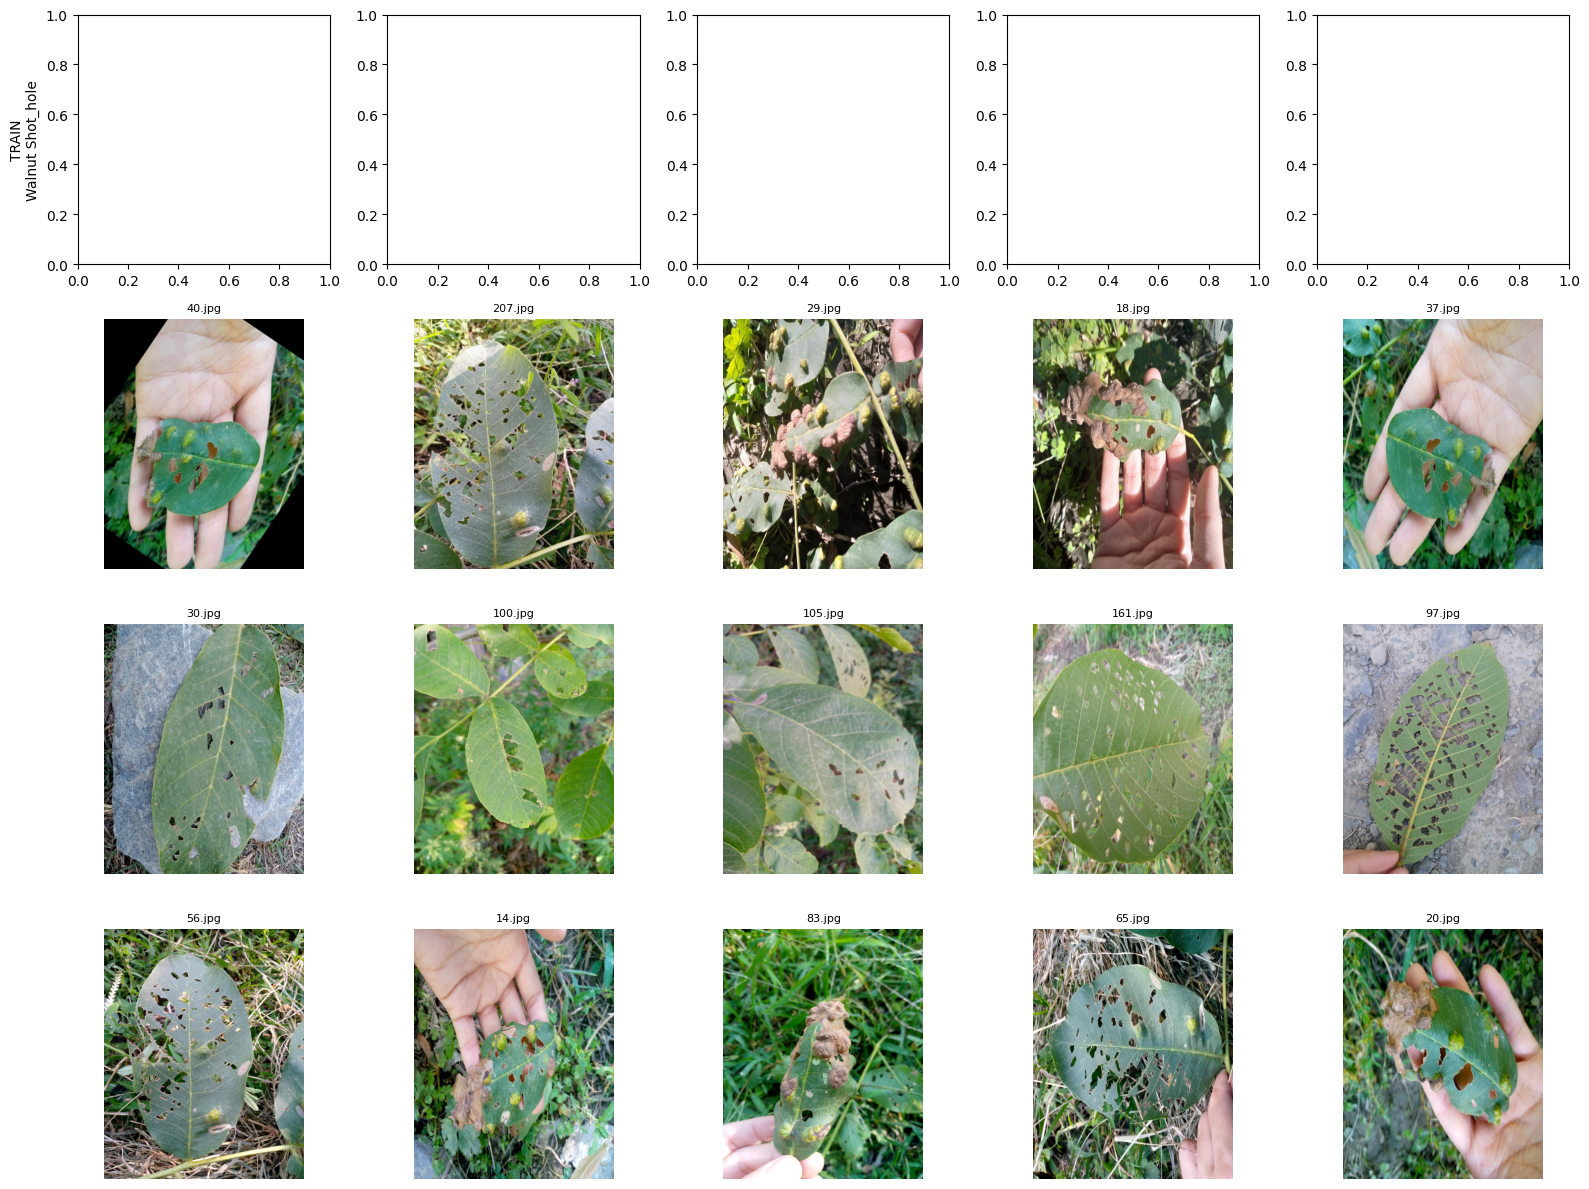

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/content/PlantCity_Dataset"

classes_to_check = [
    ("train", "Walnut Shot_hole"),
    ("train", "Walnut leaf gall mite"),
    ("test", "Walnut Shot_hole"),
    ("test", "Walnut leaf gall mite")
]

fig, axes = plt.subplots(4, 5, figsize=(16, 12))

for row, (split, class_name) in enumerate(classes_to_check):

    folder = os.path.join(base_path, split, class_name)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
        and os.path.getsize(os.path.join(folder, f)) > 0
    ]

    samples = random.sample(files, min(5, len(files)))

    for col, filename in enumerate(samples):
        img_path = os.path.join(folder, filename)

        img = Image.open(img_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(filename, fontsize=8)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"{split.upper()}\n{class_name}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Detailed Investigation of Walnut Shot_hole vs. Walnut leaf gall mite
Let's run a set of structural, visual, and statistical diagnostics to identify the root cause of this 100% recall failure for `Walnut Shot_hole`.

Content of 'train' directory (truncated): ['Apple Brown_spot', 'Apple Normal', 'Apple black_spot', 'Apricot Normal', 'Apricot blight leaf disease', 'Apricot shot_hole', 'Bean Fungal_leaf disease', 'Bean Normal leaf', 'Bean bean rust image', 'Bean shot_hole', 'Cherry Leaf Scorch', 'Cherry Normal leaf', 'Cherry brown_spot', 'Cherry purple leaf spot', 'Cherry_shot hole disease']
Content of 'test' directory (truncated): ['Apple Brown_spot', 'Apple Normal', 'Apple black_spot', 'Apricot Normal', 'Apricot blight leaf disease', 'Apricot shot_hole', 'Bean Fungal_leaf disease', 'Bean Normal leaf', 'Bean bean rust image', 'Bean shot_hole', 'Cherry Leaf Scorch', 'Cherry Normal leaf', 'Cherry brown_spot', 'Cherry purple leaf spot', 'Cherry_shot hole disease']
No valid images in folder: /content/PlantCity_Dataset/train/Walnut Shot_hole


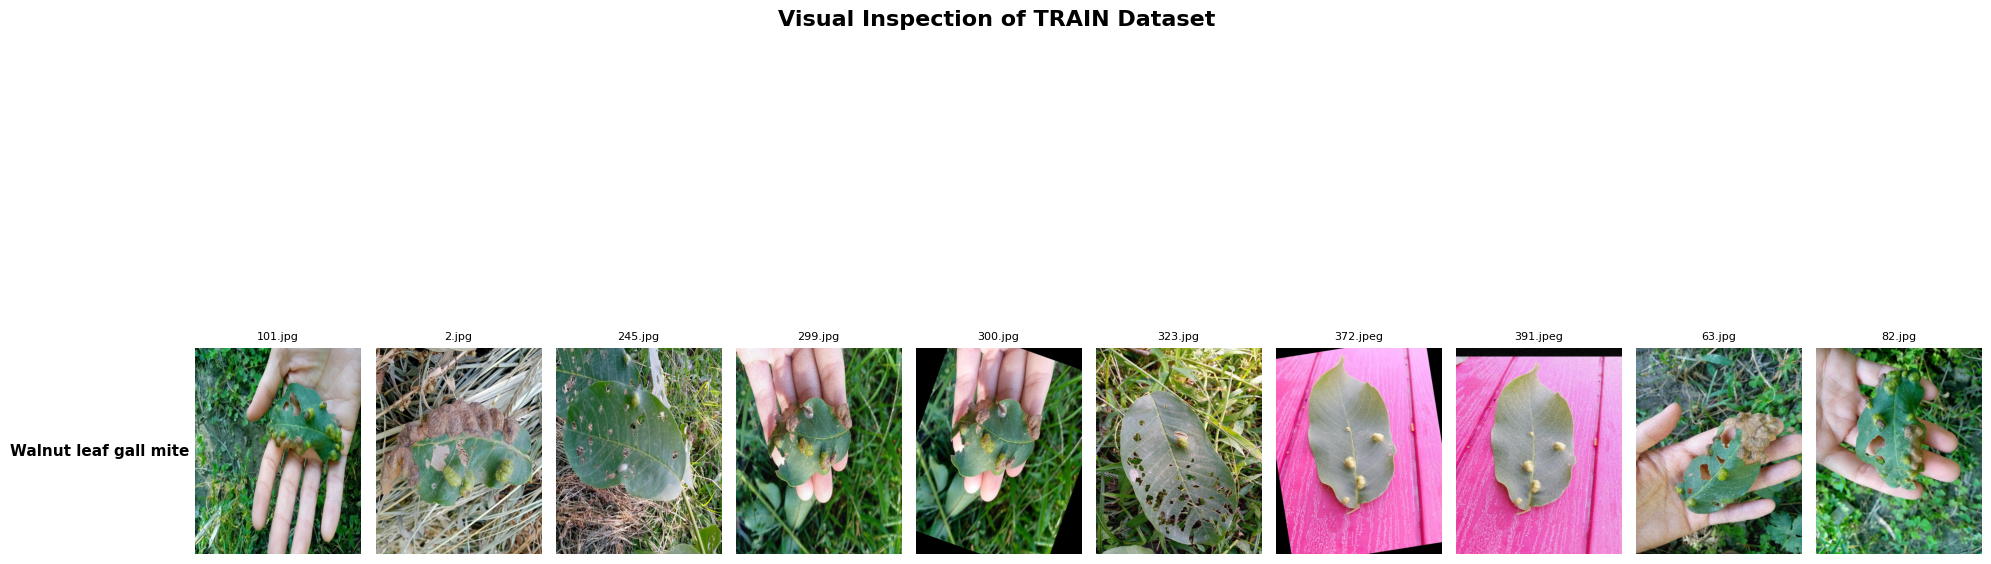

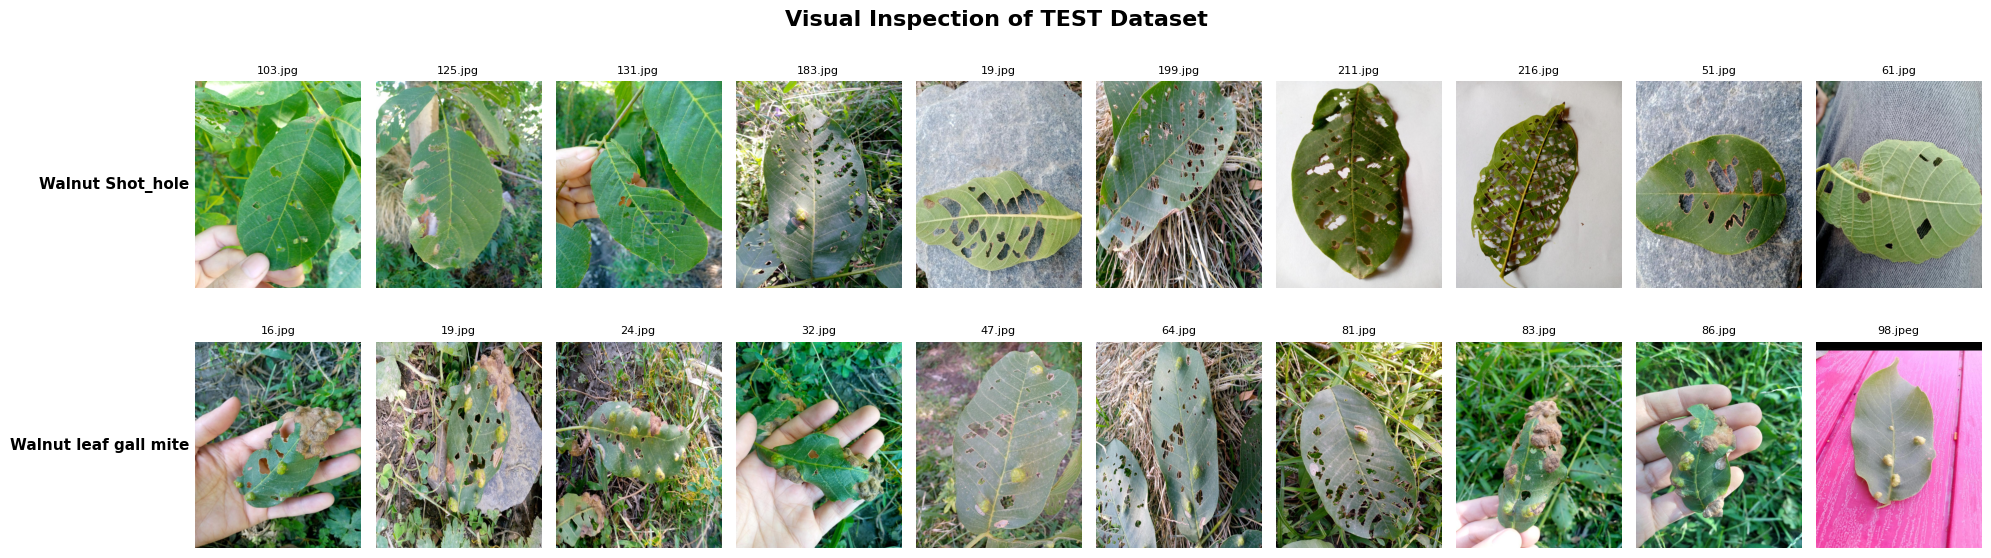

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def compare_walnut_classes(base_path, num_images=10):
    target_classes = ["Walnut Shot_hole", "Walnut leaf gall mite"]
    splits = ["train", "test"]

    for split in splits:
        split_dir = os.path.join(base_path, split)
        if os.path.exists(split_dir):
            print(f"Content of '{split}' directory (truncated):", sorted(os.listdir(split_dir))[:15])

    for split in splits:
        fig, axes = plt.subplots(2, num_images, figsize=(20, 6))
        fig.suptitle(f"Visual Inspection of {split.upper()} Dataset", fontsize=16, fontweight='bold')

        for row, class_name in enumerate(target_classes):
            folder = os.path.join(base_path, split, class_name)
            if not os.path.exists(folder):
                print(f"Folder not found: {folder}")
                for col in range(num_images):
                    axes[row, col].axis("off")
                continue

            all_files = [
                f for f in os.listdir(folder)
                if f.lower().endswith(('.jpg', '.jpeg', '.png')) and os.path.getsize(os.path.join(folder, f)) > 0
            ]

            if len(all_files) == 0:
                print(f"No valid images in folder: {folder}")
                for col in range(num_images):
                    axes[row, col].axis("off")
                continue

            sampled_files = sorted(random.sample(all_files, min(num_images, len(all_files))))

            img_width, img_height = 224, 224
            for col, file_name in enumerate(sampled_files):
                img_path = os.path.join(folder, file_name)
                img = Image.open(img_path).convert("RGB")
                img_width, img_height = img.size

                axes[row, col].imshow(img)
                axes[row, col].set_title(f"{file_name}", fontsize=8)
                axes[row, col].axis("off")

            for col in range(len(sampled_files), num_images):
                axes[row, col].axis("off")

            axes[row, 0].text(-30, img_height//2, class_name, rotation=0,
                              verticalalignment='center', horizontalalignment='right',
                              fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.show()

compare_walnut_classes("/content/PlantCity_Dataset", num_images=10)

In [ ]:
import os

train_path = "/content/PlantCity_Dataset/train"
test_path = "/content/PlantCity_Dataset/test"

train_folders = set(os.listdir(train_path))
test_folders = set(os.listdir(test_path))

print("=== Folder naming check ===")
print("Folders only in train:", sorted(list(train_folders - test_folders)))
print("Folders only in test:", sorted(list(test_folders - train_folders)))

print("\n=== Checking all folders containing 'Walnut' in training split ===")
print([f for f in train_folders if 'walnut' in f.lower()])

print("\n=== Checking all folders containing 'Walnut' in test split ===")
print([f for f in test_folders if 'walnut' in f.lower()])

=== Folder naming check ===
Folders only in train: []
Folders only in test: []

=== Checking all folders containing 'Walnut' in training split ===
['Walnut Blotch_leaf disease', 'Walnut leaf gall mite', 'Walnut Shot_hole', 'Walnut Anthracnose_leaf disease', 'Walnut Normal_leaf']

=== Checking all folders containing 'Walnut' in test split ===
['Walnut Blotch_leaf disease', 'Walnut leaf gall mite', 'Walnut Shot_hole', 'Walnut Anthracnose_leaf disease', 'Walnut Normal_leaf']


In [ ]:
# 2. Analyze prediction confidence distribution for Walnut Shot_hole
sh_idx = class_names.index("Walnut Shot_hole")
gall_idx = class_names.index("Walnut leaf gall mite")

sh_mask = (y_true == sh_idx)
sh_probabilities = y_prob[sh_mask]
sh_predictions = y_pred[sh_mask]

print(f"--- Walnut Shot_hole (Total images in Test: {sh_mask.sum()}) ---")
print(f"Mean confidence score of all test images: {np.mean(np.max(sh_probabilities, axis=1))*100:.2f}%")

# Filter to those predicted as Walnut leaf gall mite
predicted_as_gall_mask = (sh_predictions == gall_idx)
gall_predictions_prob = sh_probabilities[predicted_as_gall_mask]
if len(gall_predictions_prob) > 0:
    mean_conf_gall = np.mean(gall_predictions_prob[:, gall_idx]) * 100
    max_conf_gall = np.max(gall_predictions_prob[:, gall_idx]) * 100
    min_conf_gall = np.min(gall_predictions_prob[:, gall_idx]) * 100
    print(f"Predicted as 'Walnut leaf gall mite': {predicted_as_gall_mask.sum()} images")
    print(f"  - Mean Confidence of this misclassification: {mean_conf_gall:.2f}%")
    print(f"  - Range: [{min_conf_gall:.2f}% to {max_conf_gall:.2f}%]")

--- Walnut Shot_hole (Total images in Test: 231) ---
Mean confidence score of all test images: 86.80%
Predicted as 'Walnut leaf gall mite': 147 images
  - Mean Confidence of this misclassification: 93.10%
  - Range: [43.15% to 100.00%]


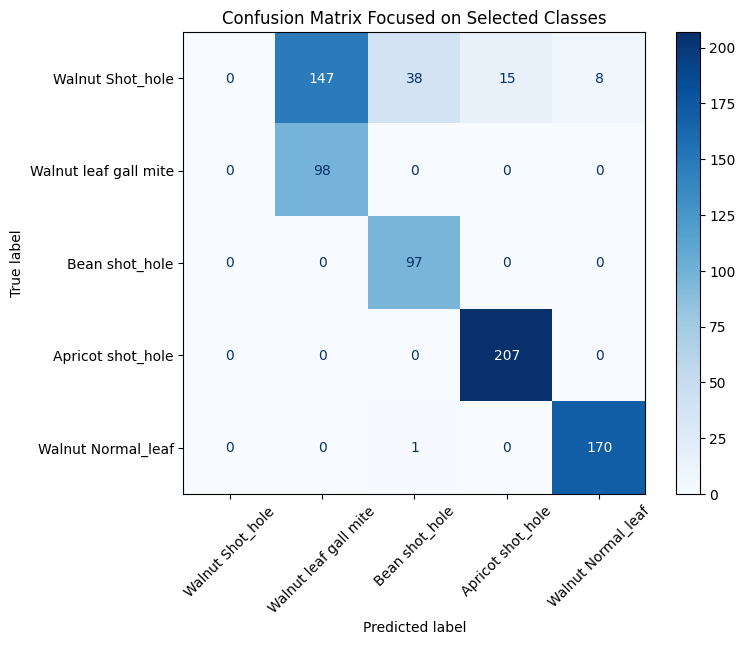

In [ ]:
# 3. Confusion Matrix focusing on Walnut and Shot_hole related classes
focused_classes = [
    "Walnut Shot_hole",
    "Walnut leaf gall mite",
    "Bean shot_hole",
    "Apricot shot_hole",
    "Walnut Normal_leaf"
]
focused_indices = [class_names.index(c) for c in focused_classes]

# Mask where true label belongs to our focused classes
focus_mask = np.isin(y_true, focused_indices)
y_true_focused = y_true[focus_mask]
y_pred_focused = y_pred[focus_mask]

# Map back to focused class labels for readable plotting
cm = confusion_matrix(y_true_focused, y_pred_focused, labels=focused_indices)

plt.figure(figsize=(8, 6))
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=focused_classes)
cmd.plot(cmap=plt.cm.Blues, xticks_rotation=45, ax=plt.gca())
plt.title("Confusion Matrix Focused on Selected Classes")
plt.show()

In [ ]:
import os
import json
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/PlantCity_Dataset/Model_Backups"
os.makedirs(save_dir, exist_ok=True)

# Save the best model used for test evaluation
evaluation_model.save(
    os.path.join(save_dir, "PlantCity_MobileNetV2_Best.keras")
)

# Save the 52 class labels
with open(os.path.join(save_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

print("MODEL AND CLASS LABELS SAVED SUCCESSFULLY!")
print("Location:", save_dir)

MODEL AND CLASS LABELS SAVED SUCCESSFULLY!
Location: /content/drive/MyDrive/PlantCity_Dataset/Model_Backups


In [ ]:
import os

folder = "/content/drive/MyDrive/PlantCity_Dataset/MultiOrgan_Datasets"

print(os.listdir(folder))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PlantCity_Dataset/MultiOrgan_Datasets'

In [ ]:
import os

base = "/content/drive/MyDrive/PlantCity_Dataset"

print("PlantCity folder exists:", os.path.exists(base))

if os.path.exists(base):
    print("\nContents:")
    for item in os.listdir(base):
        print(item)
else:
    print("Google Drive may need to be mounted.")

PlantCity folder exists: False
Google Drive may need to be mounted.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
import os
import json
import shutil
import zipfile
import tensorflow as tf

# Search both possible project folders
roots = [
    "/content/drive/MyDrive/PlantCity_Dataset (1)",
    "/content/drive/MyDrive/PlantCity_Dataset"
]

model_matches = []

for root in roots:
    if os.path.exists(root):
        for current, dirs, files in os.walk(root):
            if "PlantCity_MobileNetV2_Repaired.keras" in files:
                model_file = os.path.join(
                    current,
                    "PlantCity_MobileNetV2_Repaired.keras"
                )

                labels_file = os.path.join(
                    current,
                    "class_names.json"
                )

                if os.path.exists(labels_file):
                    model_matches.append(
                        (model_file, labels_file)
                    )

assert model_matches, "PlantCity model or labels not found!"

# Use the saved model and matching labels
model_path, labels_path = model_matches[0]

print("PlantCity model found:", model_path)

# Load labels
with open(labels_path, "r") as f:
    class_names = json.load(f)

assert len(class_names) == 52, "Expected 52 classes!"

# Load Keras model
plant_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Input shape:", plant_model.input_shape)
print("Output shape:", plant_model.output_shape)

assert plant_model.input_shape[1:] == (224, 224, 3)
assert plant_model.output_shape[-1] == 52

# Convert to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(
    plant_model
)

tflite_data = converter.convert()

# Create Android deployment folder
deployment_dir = (
    "/content/drive/MyDrive/PlantCity_Dataset (1)/"
    "Android_Deployment"
)

os.makedirs(deployment_dir, exist_ok=True)

# Save PlantCity model
plant_tflite = os.path.join(
    deployment_dir,
    "PlantCity_MobileNetV2_FP32.tflite"
)

with open(plant_tflite, "wb") as f:
    f.write(tflite_data)

# Copy PlantCity class labels
shutil.copy2(
    labels_path,
    os.path.join(deployment_dir, "class_names.json")
)

# Multi-organ model and metadata
multi_base = (
    "/content/drive/MyDrive/PlantCity_Dataset (1)/"
    "MultiOrgan_Dataset"
)

multi_model = os.path.join(
    multi_base,
    "Tomato_MultiOrgan_MobileNetV2_FP32.tflite"
)

multi_metadata = os.path.join(
    multi_base,
    "Tomato_MultiOrgan_Metadata.json"
)

assert os.path.exists(multi_model)
assert os.path.exists(multi_metadata)

shutil.copy2(multi_model, deployment_dir)
shutil.copy2(multi_metadata, deployment_dir)

print("\n========== ANDROID FILES READY ==========")

for filename in os.listdir(deployment_dir):
    path = os.path.join(deployment_dir, filename)
    print(filename, round(os.path.getsize(path)/(1024*1024), 2), "MB")

AssertionError: PlantCity model or labels not found!

In [ ]:
import os

drive = "/content/drive/MyDrive"

folders = [
    os.path.join(drive, "PlantCity_Dataset"),
    os.path.join(drive, "PlantCity_Dataset (1)")
]

for folder in folders:
    print("\n==========", folder, "==========")

    if not os.path.exists(folder):
        print("Folder not found")
        continue

    print("Contents:", os.listdir(folder))

    backup = os.path.join(folder, "Model_Backups")

    if os.path.exists(backup):
        print("\nMODEL BACKUPS:")
        for filename in os.listdir(backup):
            print(filename)
    else:
        print("\nModel_Backups folder not found")


========== /content/drive/MyDrive/PlantCity_Dataset ==========
Folder not found

========== /content/drive/MyDrive/PlantCity_Dataset (1) ==========
Folder not found


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

root = "/content/drive/MyDrive"

targets = [
    "PlantCity_MobileNetV2_Repaired.keras",
    "PlantCity_MobileNetV2_Best.keras",
    "class_names.json",
    "Tomato_MultiOrgan_MobileNetV2_FP32.tflite",
    "Tomato_MultiOrgan_Metadata.json"
]

print("========== SEARCHING GOOGLE DRIVE ==========")

for current, dirs, files in os.walk(root):
    for target in targets:
        if target in files:
            print(target)
            print("Location:", os.path.join(current, target))
            print()

========== SEARCHING GOOGLE DRIVE ==========
PlantCity_MobileNetV2_Repaired.keras
Location: /content/drive/MyDrive/PlantCity_Dataset (1)/Model_Backups/PlantCity_MobileNetV2_Repaired.keras

PlantCity_MobileNetV2_Best.keras
Location: /content/drive/MyDrive/PlantCity_Dataset (1)/Model_Backups/PlantCity_MobileNetV2_Best.keras

class_names.json
Location: /content/drive/MyDrive/PlantCity_Dataset (1)/Model_Backups/class_names.json

Tomato_MultiOrgan_MobileNetV2_FP32.tflite
Location: /content/drive/MyDrive/PlantCity_Dataset (1)/MultiOrgan_Dataset/Tomato_MultiOrgan_MobileNetV2_FP32.tflite

Tomato_MultiOrgan_Metadata.json
Location: /content/drive/MyDrive/PlantCity_Dataset (1)/MultiOrgan_Dataset/Tomato_MultiOrgan_Metadata.json



In [ ]:
import os
import tensorflow as tf
import json
import shutil
import zipfile

# Exact paths
base = "/content/drive/MyDrive/PlantCity_Dataset (1)"

plant_model_path = (
    base + "/Model_Backups/PlantCity_MobileNetV2_Repaired.keras"
)

class_path = (
    base + "/Model_Backups/class_names.json"
)

multi_base = base + "/MultiOrgan_Dataset"

multi_model_path = (
    multi_base + "/Tomato_MultiOrgan_MobileNetV2_FP32.tflite"
)

multi_metadata_path = (
    multi_base + "/Tomato_MultiOrgan_Metadata.json"
)

# Verify files
for path in [
    plant_model_path,
    class_path,
    multi_model_path,
    multi_metadata_path
]:
    assert os.path.exists(path), f"Missing file: {path}"

# Load PlantCity labels
with open(class_path, "r") as f:
    class_names = json.load(f)

assert len(class_names) == 52

# Load repaired PlantCity model
plant_model = tf.keras.models.load_model(
    plant_model_path,
    compile=False
)

print("PlantCity model loaded:", plant_model.input_shape)
print("Output shape:", plant_model.output_shape)

assert plant_model.output_shape[-1] == 52

# Convert to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(
    plant_model
)

plant_tflite_data = converter.convert()

# Deployment directory
deploy = base + "/Android_Deployment"
os.makedirs(deploy, exist_ok=True)

# Save converted PlantCity model
plant_tflite_path = (
    deploy + "/PlantCity_MobileNetV2_FP32.tflite"
)

with open(plant_tflite_path, "wb") as f:
    f.write(plant_tflite_data)

# Copy class labels
shutil.copy2(
    class_path,
    deploy + "/class_names.json"
)

# Copy multi-organ model
shutil.copy2(
    multi_model_path,
    deploy + "/Tomato_MultiOrgan_MobileNetV2_FP32.tflite"
)

# Copy multi-organ metadata
shutil.copy2(
    multi_metadata_path,
    deploy + "/Tomato_MultiOrgan_Metadata.json"
)

print("\n========== DEPLOYMENT FILES ==========")

for name in os.listdir(deploy):
    path = os.path.join(deploy, name)
    print(name, ":", round(os.path.getsize(path)/(1024*1024), 2), "MB")



PlantCity model loaded: (None, 224, 224, 3)
Output shape: (None, 52)
Saved artifact at '/tmp/tmp8th2cbsh'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 52), dtype=tf.float32, name=None)
Captures:
  137132907080656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907081232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907081040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907080464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907081616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907081808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907082576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907082384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137132907081424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1371329070808

In [ ]:
import tensorflow as tf
import json
import os

base = "/content/drive/MyDrive/PlantCity_Dataset (1)/Android_Deployment"

model_path = os.path.join(
    base, "PlantCity_MobileNetV2_FP32.tflite"
)

labels_path = os.path.join(
    base, "class_names.json"
)

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

with open(labels_path, "r") as f:
    class_names = json.load(f)

print("========== PLANTCITY TFLITE VALIDATION ==========")
print("Input shape:", input_details[0]["shape"])
print("Input type:", input_details[0]["dtype"])
print("Output shape:", output_details[0]["shape"])
print("Output type:", output_details[0]["dtype"])
print("Number of labels:", len(class_names))

assert tuple(input_details[0]["shape"][1:]) == (224, 224, 3)
assert len(class_names) == 52
assert output_details[0]["shape"][-1] == 52

print("\nPLANTCITY MODEL VALIDATION PASSED!")

========== PLANTCITY TFLITE VALIDATION ==========
Input shape: [  1 224 224   3]
Input type: <class 'numpy.float32'>
Output shape: [ 1 52]
Output type: <class 'numpy.float32'>
Number of labels: 52

PLANTCITY MODEL VALIDATION PASSED!


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
import os
import zipfile

deploy = (
    "/content/drive/MyDrive/PlantCity_Dataset (1)/"
    "Android_Deployment"
)

package = (
    "/content/drive/MyDrive/PlantCity_Dataset (1)/"
    "Android_Deployment.zip"
)

required = [
    "PlantCity_MobileNetV2_FP32.tflite",
    "class_names.json",
    "Tomato_MultiOrgan_MobileNetV2_FP32.tflite",
    "Tomato_MultiOrgan_Metadata.json"
]

for name in required:
    path = os.path.join(deploy, name)
    assert os.path.exists(path), f"Missing: {name}"

with zipfile.ZipFile(
    package, "w", zipfile.ZIP_DEFLATED
) as z:
    for name in required:
        z.write(
            os.path.join(deploy, name),
            arcname=name
        )

print("ANDROID PACKAGE READY!")
print("Location:", package)
print("Files:")

with zipfile.ZipFile(package, "r") as z:
    for name in z.namelist():
        print("-", name)

print(
    "Package size:",
    round(os.path.getsize(package) / (1024*1024), 2),
    "MB"
)

ANDROID PACKAGE READY!
Location: /content/drive/MyDrive/PlantCity_Dataset (1)/Android_Deployment.zip
Files:
- PlantCity_MobileNetV2_FP32.tflite
- class_names.json
- Tomato_MultiOrgan_MobileNetV2_FP32.tflite
- Tomato_MultiOrgan_Metadata.json
Package size: 17.08 MB
